In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import networkx as nx
import numpy as np
from scipy.integrate import solve_ivp
from sympy import symbols, sympify
import torch

from mlmmint.Models.MechanisticModel import ComplexODEMechanisticModel
from mlmmint.RegulatoryNetwork import RegulatoryNetwork

In [9]:
import sympy

# 1) Define parameter dictionary
param_dict = {
    "pSPA": 1.0, "dSPA": 0.1, "assCOP1SPA1": 0.2, "dissCOP1SPA1": 0.05,
    "pCOP1": 1.0, "dCOP1": 0.1, "iCOP1_light": 0.1, "iCOP1_drought": 0.1,
    "iCOP1_heat_shoot": 1.0, "pCOP1_heat_shoot": 1.0, "iCOP1_SPA1_auto": 0.1,
    # Add any other missing parameters here
}

# 2) Define ODEs as lambdas that take the full state‐dict
ODE_dict = {
    "spa1_shoot": lambda s: (
        param_dict["pSPA"]
        - param_dict["dSPA"] * s["spa1_shoot"]
        - param_dict["assCOP1SPA1"] * s["cop1_shoot"] * s["spa1_shoot"]
        + param_dict["dissCOP1SPA1"] * s["cop1_spa1_shoot"]
    ),
    "cop1_shoot": lambda s: (
        param_dict["pCOP1"] * param_dict["pCOP1_heat_shoot"]**s["heat"]
        - param_dict["dCOP1"] * s["cop1_shoot"]
        - (param_dict["iCOP1_light"]*s["light"] + param_dict["iCOP1_drought"]*s["drought"])
          * param_dict["iCOP1_heat_shoot"]**s["heat"] * s["cop1_shoot"]
        - param_dict["assCOP1SPA1"] * s["cop1_shoot"] * s["spa1_shoot"]
        + param_dict["dissCOP1SPA1"] * s["cop1_spa1_shoot"]
    ),
    "cop1_spa1_shoot": lambda s: (
        param_dict["assCOP1SPA1"] * s["cop1_shoot"] * s["spa1_shoot"]
        - param_dict["dissCOP1SPA1"] * s["cop1_spa1_shoot"]
        - param_dict["iCOP1_SPA1_auto"] * s["cop1_spa1_shoot"]**2
    ),
    # … define hy5_shoot, hy5p_shoot, spa1_root, … etc. …
}

input_dict = {
    "light": lambda t: (t % 24 <= 16),  # light on for 16 hours
    "heat": lambda t: 0,                 # no heat stress
    "drought": lambda t: 0                # no drought stress
}



# 3) Get a list of the dependencies of each equation
# dependencies = {
#     "spa1_shoot":   ["cop1_shoot", "cop1_spa1_shoot"],
#     "cop1_shoot":   ["heat", "light", "drought", "spa1_shoot", "cop1_spa1_shoot"],
#     "cop1_spa1_shoot": ["cop1_shoot", "spa1_shoot"],
# }

def build_network_from_ODE_dict(ODE_dict: dict, input_dict: dict, remove_linear_self_loops: bool = True):
    dependencies = {}
    gene_names = list(ODE_dict.keys())
    input_names = list(input_dict.keys()) if input_dict is not None else ["light", "heat", "drought"]
    for var, ODE in ODE_dict.items():
        symbolic_vars = sympy.symbols(gene_names + input_names)
        # Build a dict for the lambda
        state_dict = {v: symbolic_vars[i] for i, v in enumerate(gene_names)}
        state_dict.update({name: symbolic_vars[len(gene_names) + j] for j, name in enumerate(input_names)})
        symbolic_expr = sympy.sympify(ODE(state_dict))
        # Find all dependencies
        deps = [
            str(sym) for sym in symbolic_expr.free_symbols
            if str(sym) in gene_names or str(sym) in input_names
        ]
        # Only add self-loop if dependence on self is higher order (nonlinear)
        if remove_linear_self_loops:
            if var in deps:
                var_sym = symbolic_vars[gene_names.index(var)]
                # Check if the highest power of var is > 1
                if sympy.degree(symbolic_expr, gen=var_sym) <= 1:
                    deps.remove(var)
        dependencies[var] = deps

    G = nx.DiGraph()
    for var, ODE in ODE_dict.items():
        G.add_node(var, ODE=ODE, type="network")
    
    for input_node, time_series_func in input_dict.items():
        G.add_node(input_node, time_series_func=time_series_func, type="input")
    
    for var, deps in dependencies.items():
        for d in deps:
            G.add_edge(d, var)
    return G

G = build_network_from_ODE_dict(ODE_dict, input_dict)



# 5) Write a wrapper to produce the derivative‐vector for scipy
def network_ODE(t, y):
    state = dict(zip(ODE_dict.keys(), y))
    # Update state with input values at time t
    for input_name, input_func in input_dict.items():
        state[input_name] = input_func(t)
    # Compute derivatives for each ODE variable
    dydt = np.zeros(len(ODE_dict))
    for i, (var, ode_func) in enumerate(ODE_dict.items()):
        dydt[i] = ode_func(state)
    return dydt


# 6) Integrate the ODEs
gene_names = list(ODE_dict.keys())
y0 = np.zeros(len(gene_names)) # initial conditions
ODEsolution = solve_ivp(network_ODE, [0, 7*24], y0, method="LSODA")


# create mechanistic model
# MM = ComplexMechanisticModel(RegulatoryNetwork(G), param_dict)
param_dict_torch = {k: torch.nn.Parameter(torch.tensor(v, dtype=torch.float32)) for k, v in param_dict.items()}
MM = ComplexODEMechanisticModel(ODE_dict, input_dict, param_dict_torch)
gene_names = list(ODE_dict.keys())

# integrate the ODEs
t_span = (0, 7*24)  # time span for integration
t_points = torch.linspace(t_span[0], t_span[1], 1000)  # time points for integration
# Ensure time points are properly spaced to avoid numerical issues
# Ensure initial conditions are non-negative and consistent with the equations
y0 = torch.zeros(len(gene_names))  # initial conditions (non-zero positive values)
# Add error handling to catch potential numerical issues during integration
# try:
#     solution = MM.integrate(y0, t_points)
# except Exception as e:
#     print(f"Integration failed: {e}")
#     solution = None
# print(MM.regulatory_network.nodes, G.nodes)
MMsolution = MM.integrate(y0, t_points)
# solution = solve_ivp(MM.forward, t_span=[0, 7*24], y0=y0, method="LSODA")

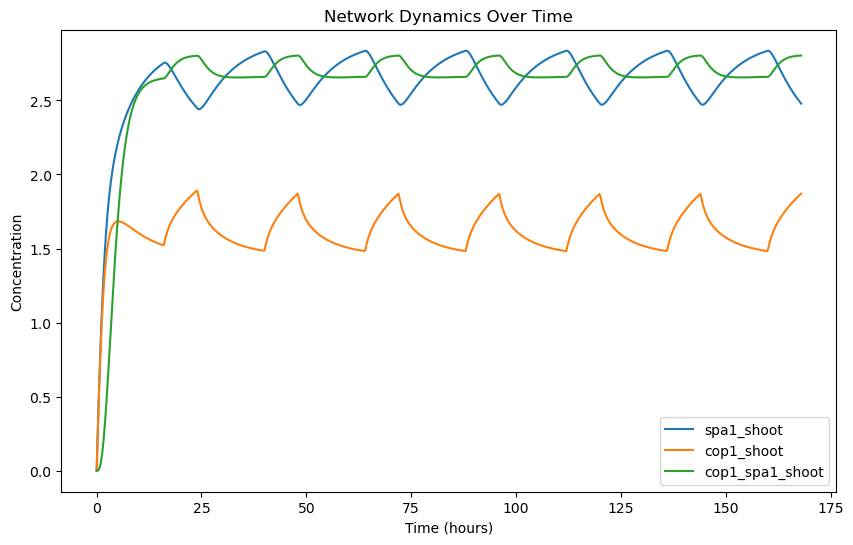

In [ ]:
# 7) Plot the results
fig, ax = plt.subplots(figsize=(10, 6))
for i, var in enumerate(gene_names):
    ax.plot(t_points, MMsolution[i], label=var)
ax.set_xlabel("Time (hours)")
ax.set_ylabel("Concentration")
ax.legend()
plt.title("Network Dynamics Over Time")
plt.show()

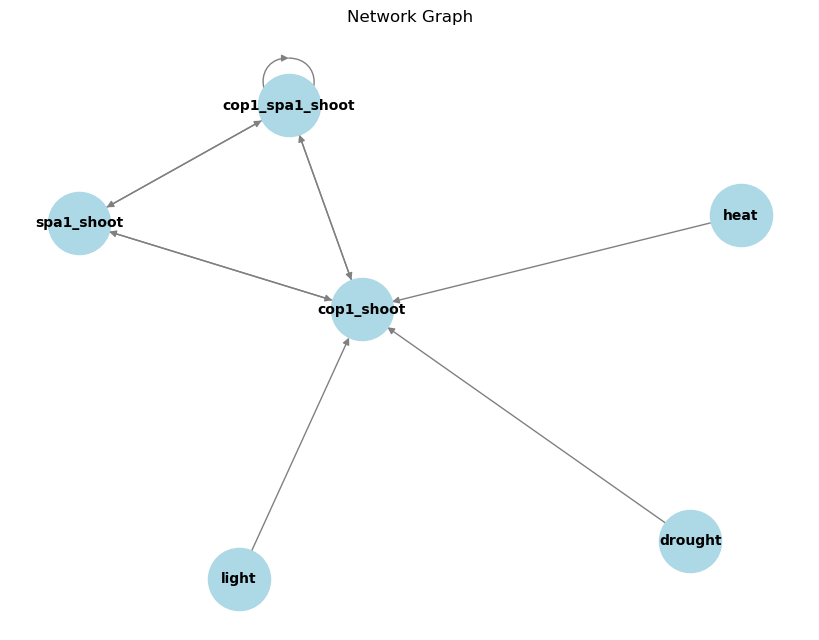

In [ ]:
G = build_network_from_ODE_dict(ODE_dict, input_dict, remove_linear_self_loops=True)
plt.figure(figsize=(8, 6))
nx.draw(G, with_labels=True, node_size=2000, node_color="lightblue", font_size=10, font_weight="bold", edge_color="gray")
plt.title("Network Graph")
plt.show()

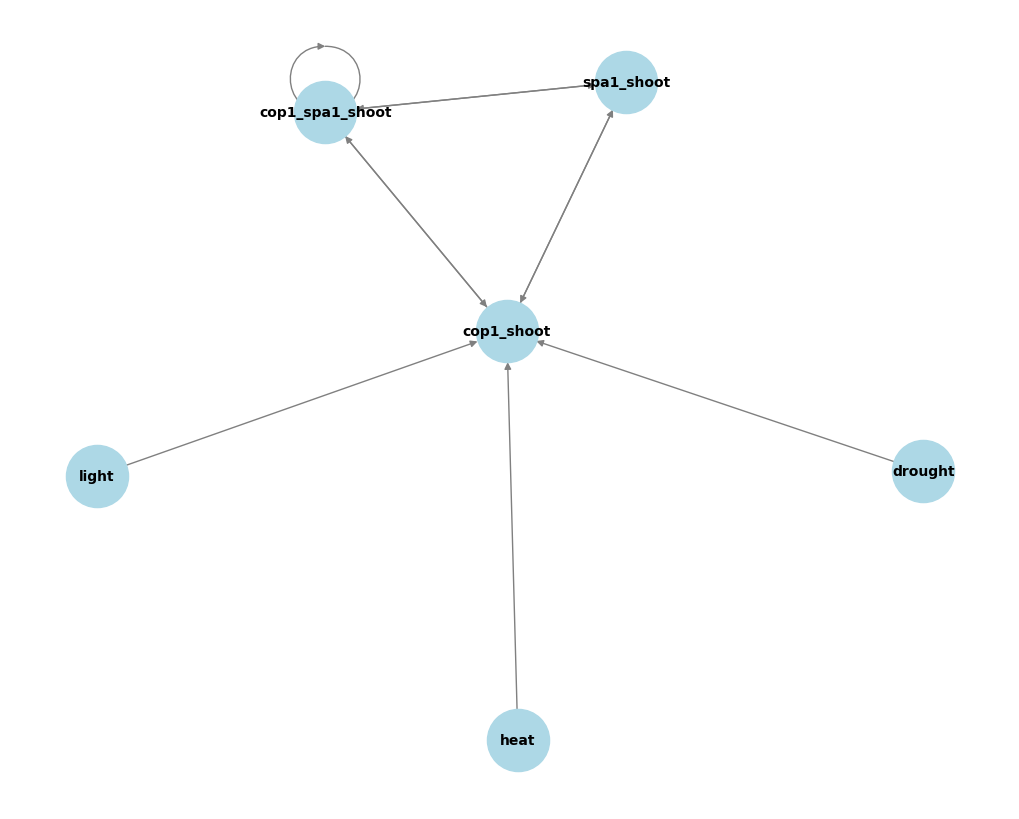

In [ ]:
MM.regulatory_network.plot()

In [ ]:
adj_matrix = nx.adjacency_matrix(G).todense()
print("Adjacency Matrix:")
print(adj_matrix)

Adjacency Matrix:
[[0 1 1 0 0 0]
 [1 0 1 0 0 0]
 [1 1 1 0 0 0]
 [0 1 0 0 0 0]
 [0 1 0 0 0 0]
 [0 1 0 0 0 0]]
